In [18]:
class LR:
  def __init__(self):
    self.m = None
    self.b = None

  def fit(self, X_train, Y_train):
    num = 0
    den = 0
    for i in range(X_train.shape[0]):
      num = num + ((X_train[i] - X_train.mean())*(Y_train[i] - Y_train.mean()))
      den = den + ((X_train[i] - X_train.mean())*(X_train[i] - X_train.mean()))
    self.m = num/den
    self.b = Y_train.mean() - (self.m * X_train.mean())
    print(self.m)
    print(self.b)

  def predict(self, X_test):
    print(X_test)
    return self.m * X_test + self.b

In [2]:
import numpy as np
import pandas as pd

In [3]:
df = pd.read_csv('placement.csv')
df.head()

,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


In [4]:
X = df.iloc[:,0:1].values
Y = df.iloc[:, -1].values

In [7]:
X

array([[6.89],
       [5.12],
       [7.82],
       [7.42],
       [6.94],
       [7.89],
       [6.73],
       [6.75],
       [6.09],
       [8.31],
       [5.32],
       [6.61],
       [8.94],
       [6.93],
       [7.73],
       [7.25],
       [6.84],
       [5.38],
       [6.94],
       [7.48],
       [7.28],
       [6.85],
       [6.14],
       [6.19],
       [6.53],
       [7.28],
       [8.31],
       [5.42],
       [5.94],
       [7.15],
       [7.36],
       [8.1 ],
       [6.96],
       [6.35],
       [7.34],
       [6.87],
       [5.99],
       [5.9 ],
       [8.62],
       [7.43],
       [9.38],
       [6.89],
       [5.95],
       [7.66],
       [5.09],
       [7.87],
       [6.07],
       [5.84],
       [8.63],
       [8.87],
       [9.58],
       [9.26],
       [8.37],
       [6.47],
       [6.86],
       [8.2 ],
       [5.84],
       [6.6 ],
       [6.92],
       [7.56],
       [5.61],
       [5.48],
       [6.34],
       [9.16],
       [7.36],
       [7.6 ],
       [5.

In [5]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)

In [19]:
X_train.shape

(160, 1)

In [20]:
lr = LR()
lr.fit(X_train, Y_train)

[0.55795197]
[-0.89611192]


In [21]:
X_test[0]

array([8.58])

In [22]:
lr.predict(X_test[0])

[8.58]


array([3.89111601])

In [28]:
#AutoMPG dataset practice
new_df = pd.read_csv('AutoMPG.csv')
new_df.head()

,Pounds in 1000s (feature),Miles per gallon (label)
0,3.50,18
1,3.69,15
2,3.44,18
3,3.43,16
4,4.34,15


In [29]:
X = new_df.iloc[:, 0:1]
Y = new_df.iloc[:, -1]

In [30]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [31]:
X_train

,Pounds in 1000s (feature)
5,4.42
2,3.44
4,4.34
3,3.43
6,2.37


In [32]:
Y_train

,Miles per gallon (label)
5,14
2,18
4,15
3,16
6,24


In [33]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, Y_train)

LinearRegression()

In [34]:
model.coef_

array([-4.4988161])

In [35]:
model.intercept_

np.float64(33.595737963693765)

In [48]:
X_train

,Pounds in 1000s (feature)
5,4.42
2,3.44
4,4.34
3,3.43
6,2.37


In [39]:
print(X_train.describe())
print("Average: ",Y_train.mean())

       Pounds in 1000s (feature)
count                   5.000000
mean                    3.600000
std                     0.834775
min                     2.370000
25%                     3.430000
50%                     3.440000
75%                     4.340000
max                     4.420000
Average:  17.4


In [51]:
# Calculation of find m and b
num = 0
den = 0
x_mean = X_train.iloc[:, 0].mean()
y_mean = Y_train.mean()

for i in range(X_train.shape[0]):
  x_val = X_train.iloc[i, 0]
  y_val = Y_train.iloc[i]
  num = num + ((x_val - x_mean) * (y_val - y_mean))
  den = den + ((x_val - x_mean) ** 2)

m = num / den
b = y_mean - m * x_mean
print("m:", m)
print("b:", b)

m: -4.498816101026047
b: 33.595737963693765


In [52]:
X_train

,Pounds in 1000s (feature)
5,4.42
2,3.44
4,4.34
3,3.43
6,2.37


In [59]:
X_test

,Pounds in 1000s (feature)
0,3.50
1,3.69


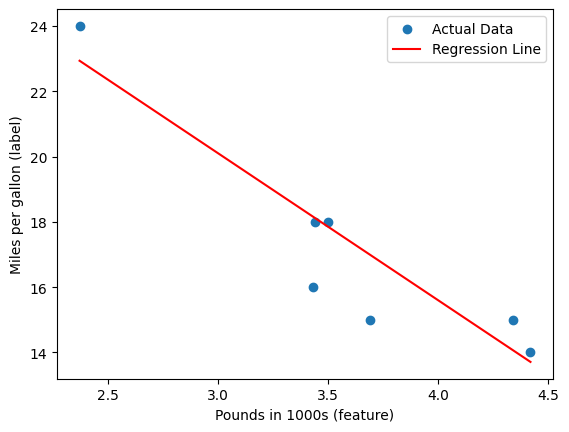

In [66]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Plot actual data points
plt.scatter(new_df['Pounds in 1000s (feature)'], new_df['Miles per gallon (label)'], label='Actual Data')

# Generate a full range of X values and wrap in a DataFrame with matching column names
x_vals = np.linspace(new_df['Pounds in 1000s (feature)'].min(), new_df['Pounds in 1000s (feature)'].max(), 100)
x_range = pd.DataFrame(x_vals, columns=['Pounds in 1000s (feature)'])

# Plot the regression line over the full range
plt.plot(x_range, model.predict(x_range), color='red', label='Regression Line')

plt.xlabel('Pounds in 1000s (feature)')
plt.ylabel('Miles per gallon (label)')
plt.legend()
plt.show()

In [61]:
model.predict(X_test)

array([17.84988161, 16.99510655])